# 🎓 第5章 第2课：基本面锚定反转

**本节目标**：用两个“锚”解释价格反转：

1. **52 周高点锚定**：价格离过去 12 个月最高点有多远？
2. **长期反转**：过去 36 个月的赢家，未来会跑输吗？

对应原书 5.2 节。

> ⚠️ 本节使用真实价格快照（87 只股票，2018-2024）；样本小、区间短，
> 结果只用于演示方法，不代表真实 A 股结论。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.data import load_ashare_panel
from factor_zero.anomalies import (
    make_teaching_fundamentals, piotroski_f_score,
    distance_from_52w_high, rolling_ivol,
)
from factor_zero.factors import build_factor_returns
from factor_zero.sorting import long_short_factor, monotonicity_test, quantile_group, sort_portfolios
from factor_zero.statistics import factor_summary, nw_t_stat

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


## 1) 52 周高点锚定：价格 / 过去 12 个月最高价

`proximity = P_t / max(P_{t-11} ... P_t)`

- 接近 1：价格贴近 52 周高点；
- 接近 0：价格离高点很远。

**行为解释**：投资者把 52 周高点当“锚”，靠近高点时容易过度乐观，远离高点时过度悲观；
锚定误差会导致价格反转。

In [2]:
panel = load_ashare_panel()
ret = panel['ret']
month_end = panel['price'].resample('ME').last().ffill().reindex(
    index=ret.index, columns=ret.columns
)
proximity = distance_from_52w_high(month_end, window=12)
print('52 周高点距离面板:', proximity.shape)
proximity.stack().describe().round(3).to_dict()

52 周高点距离面板: (83, 81)


{'count': 5832.0,
 'mean': 0.858,
 'std': 0.135,
 'min': 0.32,
 '25%': 0.778,
 '50%': 0.885,
 '75%': 0.98,
 'max': 1.0}

靠近高点 − 远离高点: 月均 -0.341%，年化 -4.09%，NW t=-0.28
分组单调性 rho=0.09


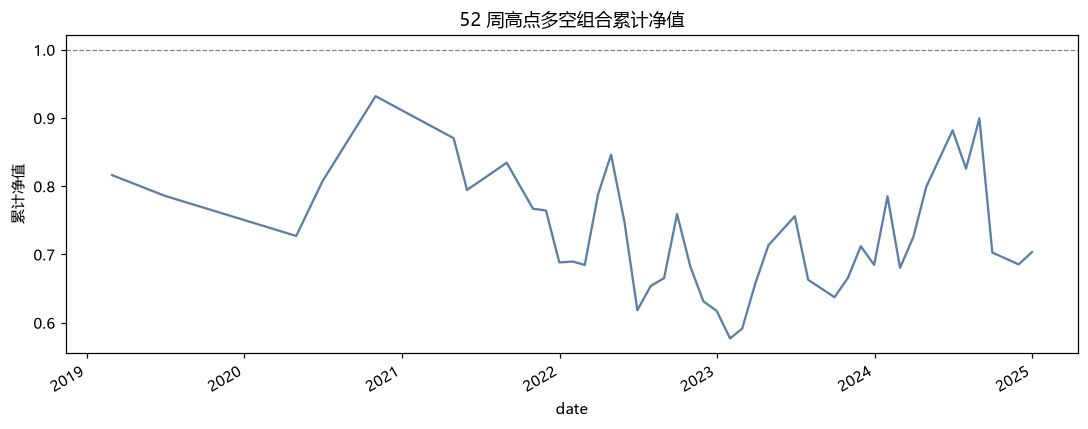

In [3]:
f52, port52, _ = long_short_factor(proximity, ret, n_groups=10, high_minus_low=True)
s52 = factor_summary(f52)
rho52 = monotonicity_test(port52)['rho']
print(f'靠近高点 − 远离高点: 月均 {f52.mean()*100:+.3f}%，年化 {s52["mean_ann"]*100:+.2f}%，NW t={s52["t_stat"]:.2f}')
print(f'分组单调性 rho={rho52:.2f}')
((1 + f52).cumprod()).plot(figsize=(10, 4), color='#5B7FA6', title='52 周高点多空组合累计净值')
plt.axhline(1, color='gray', lw=.8, ls='--'); plt.ylabel('累计净值'); plt.tight_layout(); plt.show()

## 2) 长期反转：过去 36 个月的输家 vs 赢家

构造过去 36 个月累计收益（滞后 1 个月，避免同期信息），做多输家、做空赢家。
**行为解释**：过度反应 → 长期赢家被高估、输家被低估 → 未来反转。

输家 − 赢家: 月均 +1.596%，年化 +19.15%，NW t=1.12
分组单调性 rho=-0.58


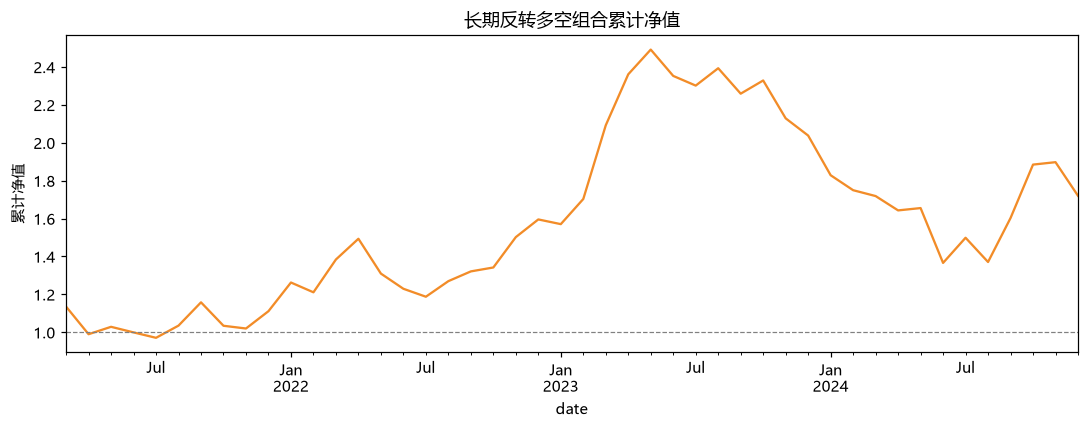

In [4]:
past36 = ret.rolling(36).sum().shift(1)
f_rev, port_rev, _ = long_short_factor(past36, ret, n_groups=10, high_minus_low=False)
s_rev = factor_summary(f_rev)
rho_rev = monotonicity_test(port_rev)['rho']
print(f'输家 − 赢家: 月均 {f_rev.mean()*100:+.3f}%，年化 {s_rev["mean_ann"]*100:+.2f}%，NW t={s_rev["t_stat"]:.2f}')
print(f'分组单调性 rho={rho_rev:.2f}')
((1 + f_rev).cumprod()).plot(figsize=(10, 4), color='#F28C28', title='长期反转多空组合累计净值')
plt.axhline(1, color='gray', lw=.8, ls='--'); plt.ylabel('累计净值'); plt.tight_layout(); plt.show()

> 🔍 **本例结果**：52 周高点多空 NW t≈−0.28，长期反转 NW t≈1.12，都不显著；
> 方向与“反转”一致，但样本小、区间短，不能据此下结论。


## 3) 两个异象的对比

| 信号 | 方向 | 经济逻辑 |
|---|---|---|
| 52 周高点距离 | 靠近高点 − 远离高点 | 锚定/过度反应 |
| 长期反转 | 输家 − 赢家 | 过度反应/均值回归 |

> 两者都可能是“反转”家族，但时间尺度和行为机制不同；相关性要看实际数据。

In [5]:
pd.DataFrame({
    '52周高点': s52,
    '长期反转': s_rev,
}).T[['mean_ann', 'vol_ann', 'sharpe', 't_stat', 'max_drawdown', 'win_rate']].round(4)

,mean_ann,vol_ann,sharpe,t_stat,max_drawdown,win_rate
52周高点,-0.0409,0.3373,-0.1213,-0.2839,-0.3809,0.4884
长期反转,0.1915,0.3200,0.5983,1.1178,-0.4518,0.5217


## ✋ 试一试

1. 把 52 周窗口从 12 个月改成 6 个月，结果怎么变？
2. 把长期反转的回看期从 36 个月改成 24 个月，显著性怎么变？
3. 把多空方向反过来，t 值符号怎么变？

## ✅ 本节小结

- 52 周高点锚定：价格离高点越远，未来可能反转；
- 长期反转：过去 36 个月的输家可能跑赢赢家；
- 两者都属于“反转/锚定”家族，但机制和时间尺度不同；
- 真实价格样本小，结果不能直接外推。

> 下一课：特质波动率——动得厉害，收益更高还是更低？